# **1. Introdução**

O Instacart é uma plataforma de compras e entrega de supermercado que conecta consumidores a estabelecimentos, permitindo que os clientes selecionem produtos on-line e recebam suas compras em casa.

Este projeto utiliza dados de pedidos da plataforma para analisar padrões de consumo e identificar comportamentos relevantes dos clientes. A base disponibilizada foi adaptada a partir dos dados originais, com redução do volume de registros para otimizar o processamento e inclusão controlada de valores ausentes e duplicados, preservando as características gerais das distribuições originais.

A análise está organizada em três etapas principais:

1. **Exploração e compreensão dos dados:** conhecer a estrutura das bases, identificar inconsistências, valores ausentes e registros duplicados.
2. **Preparação dos dados:** tratar problemas identificados, padronizar informações e garantir a consistência necessária para as análises.
3. **Análise do comportamento de compra:** investigar horários e dias de maior atividade, frequência de pedidos, quantidade de itens por compra e padrões de recompra de produtos.

Ao longo do projeto, serão utilizados métodos de análise exploratória e visualizações para identificar tendências, comparar padrões e extrair informações relevantes sobre o comportamento dos consumidores.

O objetivo é transformar os dados disponíveis em informações que contribuam para uma melhor compreensão dos hábitos de compra e possam apoiar decisões relacionadas à experiência do cliente, à gestão de produtos e às estratégias comerciais.

### **1.1 Dicionário de dados**

O conjunto de dados é composto por cinco tabelas que reúnem informações sobre pedidos, clientes, produtos e a organização dos setores de um supermercado. Essas bases serão utilizadas nas etapas de pré-processamento e Análise Exploratória de Dados (AED).

A seguir, são apresentadas as tabelas e suas respectivas colunas, com a descrição das informações armazenadas em cada uma delas.

**1. `instacart_orders.csv` — Dados dos pedidos**

Cada registro representa um pedido realizado na plataforma Instacart.

| Coluna | Descrição |
|---|---|
| `order_id` | Identificador único de cada pedido. |
| `user_id` | Identificador único da conta de cada cliente. |
| `order_number` | Número sequencial do pedido realizado pelo cliente. |
| `order_dow` | Dia da semana em que o pedido foi realizado (0 representa domingo). |
| `order_hour_of_day` | Hora do dia em que o pedido foi realizado. |
| `days_since_prior_order` | Quantidade de dias desde o pedido anterior do cliente. |

**2. `products.csv` — Cadastro de produtos**

Cada registro representa um produto disponível para compra na plataforma.

| Coluna | Descrição |
|---|---|
| `product_id` | Identificador único de cada produto. |
| `product_name` | Nome do produto. |
| `aisle_id` | Identificador do corredor ao qual o produto está associado. |
| `department_id` | Identificador do departamento ao qual o produto pertence. |

**3. `order_products.csv` — Itens dos pedidos**

Cada registro representa um produto incluído em um pedido.

| Coluna | Descrição |
|---|---|
| `order_id` | Identificador único do pedido ao qual o item pertence. |
| `product_id` | Identificador do produto incluído no pedido. |
| `add_to_cart_order` | Posição sequencial em que o produto foi adicionado ao carrinho. |
| `reordered` | Indicador de recompra: 0 quando o cliente nunca havia comprado o produto anteriormente e 1 quando já havia realizado essa compra. |

**4. `aisles.csv` — Cadastro de corredores**

Cada registro representa um corredor ou categoria de produtos do supermercado.

| Coluna | Descrição |
|---|---|
| `aisle_id` | Identificador único de cada corredor. |
| `aisle` | Nome do corredor ou categoria. |

**5. `departments.csv` — Cadastro de departamentos**

Cada registro representa um departamento do supermercado.

| Coluna | Descrição |
|---|---|
| `department_id` | Identificador único de cada departamento. |
| `department` | Nome do departamento. |

# **2. Etapa 1 — Visão geral dos dados**

Nesta etapa, serão carregadas e examinadas as cinco bases de dados do projeto: `instacart_orders.csv`, `products.csv`, `aisles.csv`, `departments.csv` e `order_products.csv`.

A leitura dos arquivos será realizada com a função `pd.read_csv()`, da biblioteca Pandas. Em seguida, será feita uma análise inicial da estrutura de cada conjunto de dados, incluindo dimensões, tipos de variáveis, valores ausentes e registros duplicados.

O objetivo é compreender a organização e a qualidade dos dados antes de iniciar as etapas de pré-processamento e análise exploratória.

### **2.1 Plano de solução**

Inicialmente, será importada a biblioteca Pandas, utilizada para manipulação e análise dos dados. Em seguida, os cinco arquivos CSV serão carregados em DataFrames por meio da função `pd.read_csv()`.

Após a importação, será realizada uma inspeção inicial de cada DataFrame, utilizando métodos como `.info()`, para verificar a quantidade de registros, os nomes das colunas, os tipos de dados e a presença de valores ausentes.

Essa verificação permitirá compreender a estrutura das bases e identificar possíveis inconsistências que deverão ser avaliadas e tratadas nas próximas etapas do projeto.

In [11]:
# Importe as bibliotecas
import pandas as pd

In [12]:
# leia os conjuntos de dados em DataFrames
orders = pd.read_csv('/content/instacart_orders.csv', sep=';')
products = pd.read_csv('/content/products.csv', sep=';')
aisles = pd.read_csv('/content/aisles.csv', sep=';')
departments = pd.read_csv('/content/departments.csv', sep=';')
order_products = pd.read_csv('/content/order_products.csv.zip', sep=';') # Nota: o arquivo original é um .zip no Colab

In [13]:
# imprima as informações sobre o DataFrame
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


In [14]:
# imprima as informações sobre o DataFrame
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [15]:
# imprima as informações sobre o DataFrame
aisles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


In [16]:
# imprima as informações sobre o DataFrame
departments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 468.0+ bytes


In [17]:
# imprima as informações sobre o DataFrame
order_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype  
---  ------             -----  
 0   order_id           int64  
 1   product_id         int64  
 2   add_to_cart_order  float64
 3   reordered          int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


## **Conclusões**

O carregamento e a inspeção inicial dos cinco conjuntos de dados permitiram compreender a estrutura e a organização das informações disponibilizadas. Foram identificadas as características gerais de cada DataFrame, incluindo suas dimensões, colunas, tipos de dados e possíveis valores ausentes.

A análise também evidenciou como as tabelas se complementam: os dados de pedidos, produtos e itens comprados podem ser relacionados por identificadores como `order_id` e `product_id`, enquanto `aisle_id` e `department_id` permitem associar os produtos às respectivas categorias e departamentos.

Essa visão geral estabeleceu a base necessária para as próximas etapas do projeto, permitindo compreender a composição dos dados e orientar o processo de pré-processamento. A partir desse diagnóstico inicial, será possível investigar inconsistências, avaliar registros duplicados e tratar os dados para garantir maior consistência nas análises posteriores.

# **3. Etapa 2 — Preparação dos dados**

Nesta etapa, será realizada a preparação das cinco bases de dados, com o objetivo de garantir a consistência e a qualidade das informações utilizadas nas análises.

O processo incluirá a verificação dos tipos de dados, assegurando que as colunas de identificação estejam representadas por números inteiros quando apropriado. Também serão identificados e tratados os valores ausentes, considerando suas características e o contexto de cada variável.

Além disso, serão investigados os registros duplicados para determinar sua natureza e definir o tratamento adequado, removendo aqueles que forem considerados inconsistências.

Todas as decisões de tratamento serão justificadas ao longo da etapa, com a descrição dos tipos de valores ausentes e duplicados identificados e dos procedimentos adotados.

### **3.1 Plano de solução**

Inicialmente, será realizada uma análise individual de cada DataFrame para identificar possíveis problemas relacionados à qualidade dos dados, como valores ausentes, tipos de dados inadequados e registros duplicados. Para essa verificação, serão utilizados métodos da biblioteca Pandas, como `.info()`, `.isna()`, `.duplicated()` e `.dtypes`, que permitirão examinar a estrutura e as características de cada conjunto de dados.

Na sequência, será investigada a presença de pedidos duplicados no DataFrame `instacart_orders`. Caso sejam identificadas duplicatas, será feita uma análise comparativa dos registros para verificar suas características em comum e identificar possíveis padrões relacionados ao horário e ao dia da semana em que os pedidos foram realizados.

Como parte dessa investigação, serão analisados especificamente os pedidos realizados às 2h da manhã de quartas-feiras, a fim de verificar se existe alguma relação entre esse padrão e as duplicatas identificadas.

Com base nos resultados, os registros duplicados serão tratados utilizando o método `.drop_duplicates()`. Por fim, será realizada uma nova verificação para confirmar a remoção das duplicatas e avaliar a consistência dos dados antes de prosseguir com as demais etapas de preparação.

In [18]:
# Verificar se há pedidos duplicados
orders[orders.duplicated()]

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
145574,794638,50898,24,3,2,2.0
223105,2160484,107525,16,3,2,30.0
230807,1918001,188546,14,3,2,16.0
266232,1782114,106752,1,3,2,NaN
273805,1112182,202304,84,3,2,6.0
284038,2845099,31189,11,3,2,7.0
311713,1021560,53767,3,3,2,9.0
321100,408114,68324,4,3,2,18.0
323900,1919531,191501,32,3,2,7.0
345917,2232988,82565,1,3,2,NaN


In [19]:
# verifique todos os pedidos feitos às 2h da manhã nas quartas-feiras
orders[(orders['order_hour_of_day'] == 2) &
       (orders['order_dow'] == 3)]

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
4838,2766110,162084,41,3,2,16.0
5156,2190225,138285,18,3,2,11.0
15506,553049,58599,13,3,2,7.0
18420,382357,120200,19,3,2,11.0
24691,690242,77357,2,3,2,9.0
...,...,...,...,...,...,...
457013,3384021,14881,6,3,2,30.0
458816,910166,164782,18,3,2,4.0
459635,1680532,106435,6,3,2,21.0
468324,222962,54979,59,3,2,3.0


In [20]:
# Remova pedidos duplicados
orders = orders.drop_duplicates().reset_index(drop=True)

In [21]:
# Verifique as linhas duplicadas mais uma vez
orders.duplicated().sum()

np.int64(0)

In [22]:
# Verifique novamente apenas os IDs de pedidos duplicados
orders['order_id'].duplicated().sum()

np.int64(0)

Foram identificados registros duplicados no DataFrame `orders`. Após a análise, as duplicatas foram removidas com o método `.drop_duplicates()`, e os índices foram reorganizados utilizando `.reset_index(drop=True)`. Uma nova verificação confirmou a ausência de registros duplicados, assegurando a consistência dessa base para as etapas seguintes do projeto.

### **3.2 DataFrame products**

In [23]:
# Verifique se há linhas completamente duplicadas
products[products.duplicated()]

,product_id,product_name,aisle_id,department_id


In [24]:
# Verifique apenas IDs dos produtos duplicados
products['product_id'].duplicated().sum()

np.int64(0)

In [25]:
# Verifique apenas nomes de produtos duplicados (converta os nomes para minúsculas para uma comparação melhor)
products[products['product_name'].str.lower().duplicated()]

,product_id,product_name,aisle_id,department_id
71,72,NaN,100,21
109,110,NaN,100,21
296,297,NaN,100,21
416,417,NaN,100,21
436,437,NaN,100,21
...,...,...,...,...
49689,49690,HIGH PERFORMANCE ENERGY DRINK,64,7
49690,49691,ORIGINAL PANCAKE & WAFFLE MIX,130,14
49691,49692,ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR,130,14
49692,49693,SPRING WATER BODY WASH,127,11


In [26]:
# Verifique os nomes de produtos duplicados que não estão faltando
products[(products['product_name'] != 'Unknown') &
         (products['product_name'].str.lower().duplicated())]

,product_id,product_name,aisle_id,department_id
71,72,NaN,100,21
109,110,NaN,100,21
296,297,NaN,100,21
416,417,NaN,100,21
436,437,NaN,100,21
...,...,...,...,...
49689,49690,HIGH PERFORMANCE ENERGY DRINK,64,7
49690,49691,ORIGINAL PANCAKE & WAFFLE MIX,130,14
49691,49692,ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR,130,14
49692,49693,SPRING WATER BODY WASH,127,11


Após a exclusão dos registros com valores ausentes representados por `"Unknown"`, foram identificados 104 nomes de produtos duplicados na coluna `product_name`. No entanto, a análise dos registros mostrou que esses produtos possuem `product_id` distintos. Como o identificador é utilizado para diferenciar cada produto na base de dados, a repetição dos nomes não caracteriza, por si só, duplicidade de registros. Portanto, os dados foram mantidos, preservando a identificação original dos produtos.

### **3.3 DataFrame departments**

In [27]:
# Verifique se há linhas completamente duplicadas
departments[departments.duplicated()]

,department_id,department


In [28]:
# Verifique apenas IDs duplicados de departamentos
departments['department_id'].duplicated().sum()

np.int64(0)

A análise do DataFrame `departments` não identificou registros completamente duplicados nem valores repetidos na coluna `department_id`. Esse resultado confirma que cada departamento está associado a um identificador exclusivo na base de dados. Dessa forma, não foi necessário realizar exclusões ou alterações nos registros, e o DataFrame foi mantido sem modificações.

### **3.4 DataFrame aisles**

In [29]:
# Verifique se há linhas completamente duplicadas
aisles[aisles.duplicated()]

,aisle_id,aisle


In [30]:
# Verifique apenas IDs duplicados de corredores
aisles['aisle'].str.lower().duplicated().sum()

np.int64(0)

A análise do DataFrame `aisles` não identificou registros completamente duplicados. Também foi realizada uma verificação adicional dos nomes dos corredores, após a conversão dos textos para letras minúsculas, com o objetivo de identificar possíveis duplicidades decorrentes de diferenças de capitalização. Nenhum caso duplicado foi encontrado. Portanto, não foi necessário remover ou modificar registros, e o DataFrame foi mantido sem alterações.

### **3.5 DataFrame order_products**

In [31]:
# Verifique se há linhas completamente duplicadas
order_products[order_products.duplicated()]

,order_id,product_id,add_to_cart_order,reordered


In [32]:
# Verifique mais uma vez se há outros casos complicados de duplicados
order_products.duplicated(subset=['order_id', 'product_id']).sum()

np.int64(0)

A análise do DataFrame `order_products` não identificou registros completamente duplicados nem duplicações nas combinações de identificadores de pedido (`order_id`) e produto (`product_id`). Esse resultado indica que não foram encontradas ocorrências repetidas de um mesmo produto dentro de um mesmo pedido. Portanto, não foi necessário remover ou modificar registros, e o DataFrame foi mantido sem alterações.

## **Remoção e tratamento de valores ausentes**

Durante a análise da qualidade dos dados, foram identificados valores ausentes em três colunas, distribuídas entre diferentes DataFrames:

- **`products` — `product_name`:** ausência do nome de alguns produtos.
- **`orders` — `days_since_prior_order`:** ausência da informação sobre o intervalo de dias desde o pedido anterior.
- **`order_products` — `add_to_cart_order`:** ausência da posição em que determinados produtos foram adicionados ao carrinho.

Essas ocorrências serão investigadas individualmente para compreender sua natureza e avaliar o impacto nas análises. Com base nessa avaliação, será definido o tratamento mais adequado para cada caso, considerando o significado da variável e a possibilidade de preservar as informações relevantes dos conjuntos de dados.


### **3.6 DataFrame products**

In [33]:
# Encontre valores ausentes na coluna 'product_name'
missing_product_names = products['product_name'].isna().sum()
print(f"Número de valores ausentes em 'product_name': {missing_product_names}")

Número de valores ausentes em 'product_name': 1258


A análise do DataFrame `products` identificou **1.258 valores ausentes na coluna `product_name`**, indicando que uma parcela dos registros não possui o nome do produto informado.

**Impacto na análise:** a ausência dos nomes dificulta a identificação dos produtos e pode comprometer análises que dependam dessa informação, como rankings de produtos, agrupamentos por nome e relatórios de vendas. Entretanto, os registros ainda possuem o identificador `product_id`, que permite reconhecer cada produto individualmente.

**Tratamento necessário:** antes de remover qualquer registro, é importante avaliar a possibilidade de recuperar os nomes ausentes por meio de outras informações disponíveis. Caso não seja possível recuperá-los, deve-se considerar o impacto da exclusão desses registros nas análises posteriores.

**Conclusão:** embora os valores ausentes estejam concentrados em uma única coluna, é necessário avaliar seu tratamento para evitar perda desnecessária de informações e preservar a qualidade das análises.

In [34]:
# Todos os nomes de produtos ausentes estão associados com o corredor de ID 100?
missing_products = products[products['product_name'].isna()]
# Verificar os corredores (aisle_id) desses produtos
print(missing_products['aisle_id'].value_counts())

aisle_id
100    1258
Name: count, dtype: int64


A análise revelou que os 1.258 valores ausentes na coluna `product_name` estão concentrados em produtos associados ao `aisle_id` 100, indicando que a ausência de nomes não ocorre de forma aleatória entre os corredores.

Esse padrão sugere uma possível relação entre os registros sem identificação e uma categoria específica de produtos. No entanto, os dados disponíveis não permitem afirmar que o corredor 100 representa produtos desconhecidos ou não categorizados.

**Impacto na análise:** a concentração dos valores ausentes em um único corredor permite delimitar melhor o problema e avaliar seu impacto nas análises por categoria de produtos.

**Tratamento:** antes de excluir esses registros, é importante verificar se existe alguma informação complementar que permita recuperar os nomes dos produtos. Caso isso não seja possível, os registros poderão ser mantidos separadamente ou excluídos de análises que dependam da identificação pelo nome, conforme o objetivo de cada análise.

In [35]:
# Todos os nomes de produtos ausentes estão associados com o departamento de ID 21?
# Filtrar produtos com nome ausente
missing_products = products[products['product_name'].isna()]

# Verificar os departamentos desses produtos
print(missing_products['department_id'].value_counts())

department_id
21    1258
Name: count, dtype: int64


A análise revelou que os valores ausentes na coluna `product_name` estão concentrados em registros associados ao mesmo corredor (`aisle_id = 100`) e ao mesmo departamento (`department_id = 21`). Esse padrão indica que as ausências estão relacionadas a uma categoria específica da base, e não distribuídas aleatoriamente entre os produtos.

Uma possível hipótese é que esses identificadores representem uma categoria de produtos sem classificação ou identificação disponível no sistema. No entanto, essa interpretação não pode ser confirmada apenas com as informações analisadas.

**Impacto e tratamento:** como esses registros não possuem nomes de produtos, sua utilização em análises que dependam da identificação nominal fica limitada. Por isso, podem ser tratados separadamente ou excluídos das análises específicas que utilizem essa informação, desde que a decisão não comprometa os demais resultados. A preservação dos registros também deve ser considerada, pois eles ainda possuem identificadores que permitem relacioná-los a outras informações da base.

In [36]:
# Use as tabelas department e aisle para verificar os dados do corredor com ID 100 e do departamento com ID 21.
# Verificar o departamento com ID 21
dept_21 = departments[departments['department_id'] == 21]
print("Departamento ID 21:")
print(dept_21)

# Verificar o corredor com ID 100
aisle_100 = aisles[aisles['aisle_id'] == 100]
print("\nCorredor ID 100:")
print(aisle_100)

Departamento ID 21:
    department_id department
20             21    missing

Corredor ID 100:
    aisle_id    aisle
99       100  missing


A análise identificou que todos os 1.258 registros com valores ausentes na coluna `product_name` estão associados ao mesmo corredor (`aisle_id = 100`) e departamento (`department_id = 21`), ambos relacionados à categoria de valores ausentes na base.

Esse padrão indica que os produtos não possuem classificação ou identificação nominal disponível. Embora não seja possível confirmar se esses registros representam placeholders do sistema, sua concentração sugere uma inconsistência específica na categorização dos produtos.

Para as análises e os relatórios, esses registros podem ser tratados separadamente como produtos não identificados ou não categorizados. A exclusão também pode ser considerada em análises que dependam dos nomes dos produtos, desde que sejam avaliados os possíveis impactos sobre os resultados.

In [37]:
# Preencha nomes de produtos ausentes com 'Unknown'
# Preencher valores ausentes com "Unknown"
products['product_name'] = products['product_name'].fillna('Unknown')

# Verificar se ainda há valores ausentes
missing_product_names = products['product_name'].isna().sum()
print(f"Valores ausentes em 'product_name' após preenchimento: {missing_product_names}")

Valores ausentes em 'product_name' após preenchimento: 0


**Situação identificada:** Foram encontrados 1.258 valores ausentes na coluna `product_name` do DataFrame `products`. A análise revelou que todos esses registros estavam associados ao departamento (`department_id = 21`) e ao corredor (`aisle_id = 100`), ambos identificados como `"missing"`. Essa concentração indica que os produtos não possuem informações de categorização ou identificação nominal disponíveis na base.

**Ação realizada:** Em vez de excluir os registros, os valores ausentes foram substituídos por `"Unknown"` utilizando o método `.fillna()`. Essa abordagem permitiu preservar os registros e seus respectivos identificadores, mantendo a estrutura original do conjunto de dados.

**Conclusão:** O tratamento padronizou os valores ausentes na coluna `product_name`, facilitando a identificação desses registros e evitando problemas em operações que dependam do preenchimento desse campo. Dessa forma, os dados foram preservados para análises posteriores, permitindo que os produtos sem identificação nominal sejam diferenciados daqueles que possuem nomes registrados.

### **3.7 DataFrame orders**

In [38]:
# Encontre os valores ausentes
# Verificar valores ausentes na coluna 'days_since_prior_order'
missing_days = orders['days_since_prior_order'].isna().sum()
print(f"Número de valores ausentes em 'days_since_prior_order': {missing_days}")

# Para visualizar quais linhas têm valores ausentes
missing_rows = orders[orders['days_since_prior_order'].isna()]
print(missing_rows.head())

Número de valores ausentes em 'days_since_prior_order': 28817
     order_id  user_id  order_number  order_dow  order_hour_of_day  \
28     133707   182261             1          3                 10   
96     787445    25685             1          6                 18   
100    294410   111449             1          0                 19   
103   2869915   123958             1          4                 16   
104   2521921    42286             1          3                 18   

     days_since_prior_order  
28                      NaN  
96                      NaN  
100                     NaN  
103                     NaN  
104                     NaN  


In [39]:
# Há valores ausentes para os clientes que não estão fazendo o primeiro pedido?
# Filtrar pedidos que não são o primeiro
non_first_orders = orders[orders['order_number'] > 1]

# Verificar se há valores ausentes
missing_non_first = non_first_orders['days_since_prior_order'].isna().sum()
print(f"Valores ausentes em pedidos que não são o primeiro: {missing_non_first}")

Valores ausentes em pedidos que não são o primeiro: 0


**Situação identificada:** Foram identificados 28.817 valores ausentes na coluna `days_since_prior_order` do DataFrame `orders`. A investigação revelou que todos esses registros correspondem ao primeiro pedido de cada cliente (`order_number = 1`). Não foram encontrados valores ausentes nos pedidos subsequentes (`order_number > 1`).

**Ação realizada:** Os valores ausentes foram substituídos por `0` utilizando o método `.fillna(0)`. Essa decisão considera que, no primeiro pedido registrado, não existe um pedido anterior que permita calcular o intervalo de dias. Dessa forma, o zero foi adotado como um valor representativo dessa condição.

**Conclusão:** A análise confirmou que os valores ausentes estão associados exclusivamente aos primeiros pedidos dos clientes, não representando uma inconsistência nos registros de pedidos subsequentes. O preenchimento com zero preservou todos os registros e permitiu manter a coluna sem valores ausentes, facilitando sua utilização nas análises posteriores.

### **3.8 DataFrame order_products**

In [40]:
# Encontre os valores ausentes
# Verificar valores ausentes na coluna 'add_to_cart_order'
missing_add_to_cart = order_products['add_to_cart_order'].isna().sum()
print(f"Número de valores ausentes em 'add_to_cart_order': {missing_add_to_cart}")

# Para visualizar algumas linhas com valores ausentes
missing_rows = order_products[order_products['add_to_cart_order'].isna()]
print(missing_rows.head())

Número de valores ausentes em 'add_to_cart_order': 836
       order_id  product_id  add_to_cart_order  reordered
737     2449164        5068                NaN          0
9926    1968313       43867                NaN          0
14394   2926893       11688                NaN          0
16418   1717990        4142                NaN          0
30114   1959075       42828                NaN          1


In [41]:
# Quais são os valores mínimo e máximo dessa coluna?
# Valores mínimo e máximo da coluna 'add_to_cart_order'
min_order = order_products['add_to_cart_order'].min()
max_order = order_products['add_to_cart_order'].max()

print(f"Valor mínimo em 'add_to_cart_order': {min_order}")
print(f"Valor máximo em 'add_to_cart_order': {max_order}")

Valor mínimo em 'add_to_cart_order': 1.0
Valor máximo em 'add_to_cart_order': 64.0


**Análise dos valores extremos:**

- **Valor mínimo = 1:** indica que o primeiro produto adicionado ao carrinho recebe a posição 1, conforme esperado para uma sequência de itens.
- **Valor máximo = 64:** indica que o maior pedido registrado possui 64 itens, demonstrando que existem pedidos com volumes elevados de produtos.

A verificação dos valores mínimo e máximo não identificou posições iguais a zero ou valores negativos. A coluna apresenta valores compatíveis com sua finalidade, que é registrar a ordem em que cada produto foi adicionado ao carrinho.

**Conclusão:**

A coluna `add_to_cart_order` mantém a lógica esperada de ordenação dos itens nos pedidos. Após a investigação e o tratamento dos valores ausentes, os registros estão preparados para análises relacionadas à sequência de inclusão dos produtos no carrinho e aos padrões de composição dos pedidos.

In [42]:
# Salve todos os IDs dos pedidos com pelo menos um valor ausente em 'add_to_cart_order'
# Filtrar linhas com valores ausentes
missing_add_to_cart_orders = order_products[order_products['add_to_cart_order'].isna()]

# Obter IDs únicos dos pedidos
order_ids_with_missing = missing_add_to_cart_orders['order_id'].unique()

# Mostrar alguns exemplos
print(order_ids_with_missing[:10])

[2449164 1968313 2926893 1717990 1959075  844733   61355  936852  264710
 1564093]


In [43]:
# Todos os pedidos com valores ausentes contêm mais de 64 produtos?
# Agrupe os pedidos com dados ausentes por ID de pedido
# Conte o número de 'product_id' em cada pedido e verifique o valor mínimo da contagem

# Filtrar linhas com valores ausentes
missing_add_to_cart_orders = order_products[order_products['add_to_cart_order'].isna()]

# Agrupar por order_id e contar produtos
product_counts = missing_add_to_cart_orders.groupby('order_id')['product_id'].count()

# Verificar o valor mínimo da contagem
min_products = product_counts.min()
max_products = product_counts.max()

print(f"Número mínimo de produtos em pedidos com valores ausentes: {min_products}")
print(f"Número máximo de produtos em pedidos com valores ausentes: {max_products}")

Número mínimo de produtos em pedidos com valores ausentes: 1
Número máximo de produtos em pedidos com valores ausentes: 63


### **Resumo do tratamento de valores ausentes**

Durante a etapa de preparação dos dados, foram identificados e tratados valores ausentes em três colunas:

- **`products.product_name`:** 1.258 valores ausentes, concentrados no departamento (`department_id = 21`) e corredor (`aisle_id = 100`), ambos identificados como `"missing"`. Os valores foram substituídos por `"Unknown"`, preservando os registros e seus identificadores.

- **`orders.days_since_prior_order`:** 28.817 valores ausentes, todos associados aos primeiros pedidos dos clientes (`order_number = 1`). O preenchimento foi realizado com `0`, representando a ausência de um pedido anterior.

- **`order_products.add_to_cart_order`:** 836 valores ausentes, distribuídos em um conjunto limitado de pedidos. Esses valores foram substituídos por `999`, utilizado como marcador para identificar os registros sem informação sobre a posição do produto no carrinho.

**Conclusão geral:**

Os valores ausentes foram tratados considerando as características de cada variável e o contexto em que ocorreram. A estratégia adotada permitiu preservar os registros das três bases e padronizar os campos que apresentavam informações incompletas, preparando os conjuntos de dados para as análises posteriores.

In [44]:
# Substitua valores ausentes na coluna 'add_to_cart_order' por 999 e converta a coluna para o tipo integer
# Substituir valores ausentes por 999
order_products['add_to_cart_order'] = order_products['add_to_cart_order'].fillna(999)

# Converter a coluna para tipo inteiro
order_products['add_to_cart_order'] = order_products['add_to_cart_order'].astype(int)

# Verificar resultado
print(order_products['add_to_cart_order'].dtype)
print(order_products['add_to_cart_order'].head())

int64
0    17
1     1
2     1
3    35
4     5
Name: add_to_cart_order, dtype: int64


**Situação identificada:** Foram identificados 836 valores ausentes na coluna `add_to_cart_order` do DataFrame `order_products`, distribuídos entre alguns pedidos.

**Ação realizada:** Os valores ausentes foram substituídos por `999`, utilizado como marcador para identificar os registros originalmente sem informação sobre a posição do produto no carrinho. Em seguida, a coluna foi convertida para o tipo inteiro (`int64`), preservando os valores válidos e padronizando o formato dos dados.

**Conclusão:** Após o tratamento, a coluna não apresenta mais valores ausentes (`NaN`) e mantém as posições originais dos produtos que possuíam essa informação. O valor `999` permite identificar separadamente os registros cujo posicionamento não foi informado, preservando esses dados para análises posteriores.

É importante considerar esse marcador em análises que envolvam a ordem de inclusão dos produtos no carrinho, para que o valor `999` não seja interpretado como uma posição real.

## **Conclusões**

A etapa de preparação dos dados teve como objetivo avaliar e corrigir possíveis problemas de qualidade nos cinco DataFrames, incluindo tipos de dados, valores ausentes e registros duplicados.

Durante a análise, foram identificados registros duplicados no DataFrame `orders`, que foram removidos após a investigação. Nos demais conjuntos de dados, as verificações não apontaram duplicações que justificassem a exclusão de registros.

Em relação aos valores ausentes, foram adotadas estratégias específicas de acordo com o contexto de cada variável:

- **`products.product_name`:** os 1.258 valores ausentes foram substituídos por `"Unknown"`, preservando os registros de produtos sem identificação nominal.
- **`orders.days_since_prior_order`:** os 28.817 valores ausentes foram preenchidos com `0`, pois correspondiam exclusivamente aos primeiros pedidos dos clientes, para os quais não existe um intervalo anterior a ser calculado.
- **`order_products.add_to_cart_order`:** os 836 valores ausentes foram substituídos por `999`, utilizado como marcador para identificar os registros sem informação sobre a posição do produto no carrinho, sem alterar as posições válidas.

As decisões de tratamento consideraram as características de cada coluna e buscaram preservar o máximo possível das informações originais, evitando exclusões desnecessárias.

Ao final dessa etapa, os problemas identificados foram tratados e os conjuntos de dados foram preparados para a continuidade da Análise Exploratória de Dados (AED), com maior padronização e critérios de tratamento documentados.

# **4. Etapa 3. Análise de dados**

### **4.1 Análise dos padrões de pedidos**

Nesta etapa, serão analisados os padrões de realização dos pedidos, considerando os horários, os dias da semana e os intervalos entre compras.

Inicialmente, será verificada a consistência dos valores nas colunas `order_hour_of_day` e `order_dow` do DataFrame `orders`, confirmando se os horários estão dentro do intervalo de 0 a 23 e os dias da semana entre 0 e 6.

Em seguida, serão desenvolvidas visualizações para investigar:

1. **Distribuição dos pedidos por horário:** identificar os períodos do dia com maior e menor volume de pedidos.
2. **Distribuição dos pedidos por dia da semana:** identificar os dias de maior e menor atividade na plataforma.
3. **Intervalo entre pedidos:** analisar a quantidade de dias entre compras consecutivas, observando a distribuição dos valores e seus limites mínimo e máximo.

Os resultados permitirão identificar padrões temporais no comportamento de compra dos consumidores e compreender melhor a frequência com que utilizam a plataforma.

In [45]:
# verificar valores mínimo e máximo das colunas
orders['order_hour_of_day'].min(), orders['order_hour_of_day'].max()

(0, 23)

In [46]:
orders['order_dow'].min(), orders['order_dow'].max()

(0, 6)

A verificação das colunas `order_hour_of_day` e `order_dow` confirmou que seus valores estão dentro dos intervalos esperados. A coluna `order_hour_of_day` apresenta valores entre 0 e 23, contemplando todas as horas do dia. Já a coluna `order_dow` contém valores entre 0 e 6, representando os dias da semana, sendo 0 correspondente ao domingo.

Dessa forma, não foram identificados valores fora dos intervalos válidos nessas variáveis. Os dados apresentam a estrutura esperada e podem ser utilizados nas análises temporais seguintes, permitindo investigar a distribuição dos pedidos por horário e dia da semana.

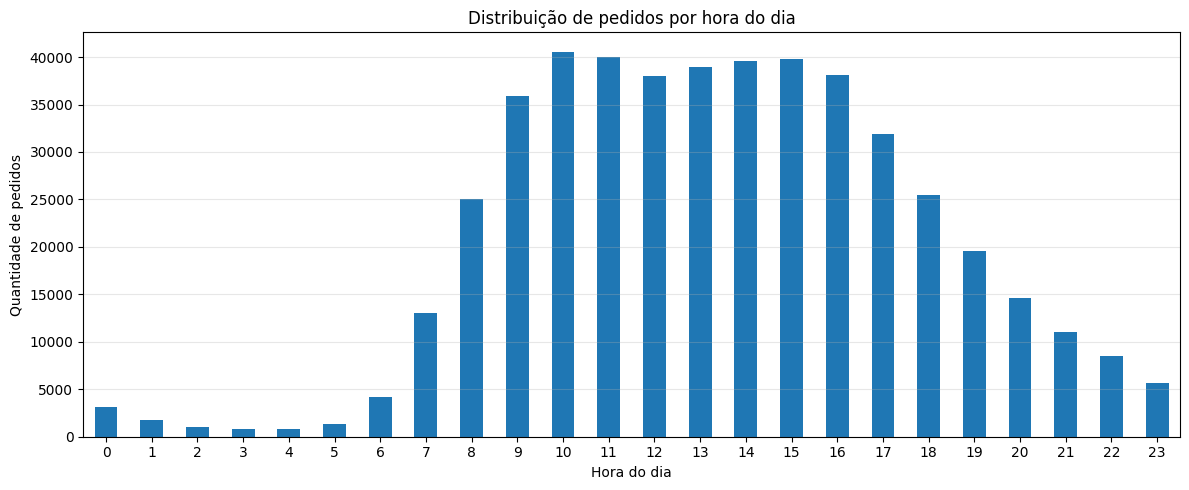

In [47]:
# Quantidade de pedidos por hora do dia
orders_per_hour = orders['order_hour_of_day'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
orders_per_hour.plot(kind='bar')

plt.title('Distribuição de pedidos por hora do dia')
plt.xlabel('Hora do dia')
plt.ylabel('Quantidade de pedidos')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Análise dos pedidos por hora do dia**

A distribuição dos pedidos apresenta maior concentração entre 9h e 16h, com pico às 10h, quando foram registrados aproximadamente 40 mil pedidos.

A partir das 7h, observa-se um crescimento expressivo no volume de compras, que permanece elevado durante boa parte do período diurno. Após as 16h, o número de pedidos diminui gradualmente.

Durante a madrugada, especialmente entre 1h e 5h, a atividade é significativamente menor.

**Conclusão:** os dados indicam que o período diurno concentra a maior parte das compras, especialmente entre o final da manhã e o meio da tarde.

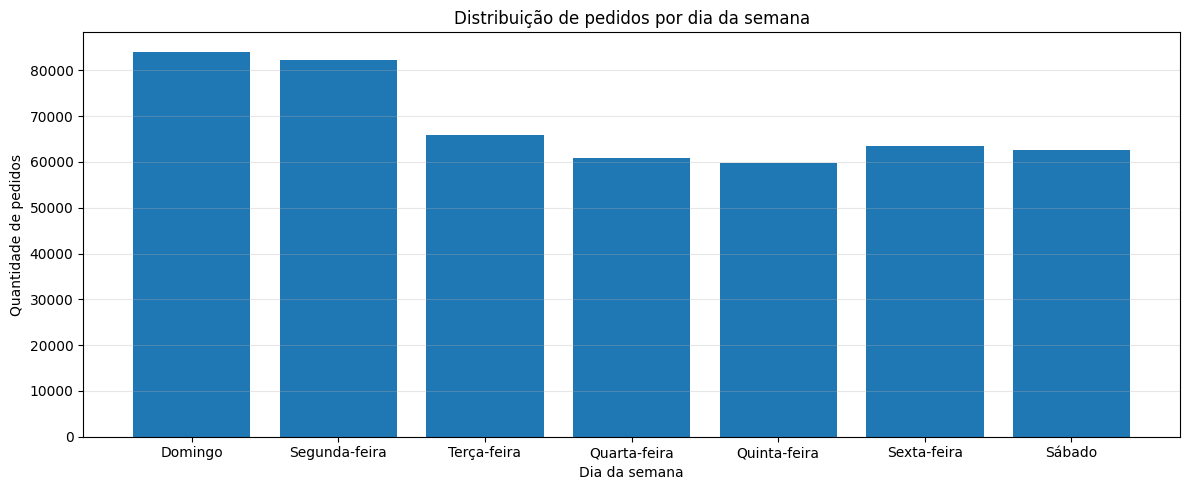

In [48]:
# Quantidade de pedidos por dia da semana
orders_per_day = orders['order_dow'].value_counts().sort_index()

dias_semana = [
    'Domingo', 'Segunda-feira', 'Terça-feira',
    'Quarta-feira', 'Quinta-feira', 'Sexta-feira', 'Sábado'
]

plt.figure(figsize=(12, 5))
plt.bar(dias_semana, orders_per_day.values)

plt.title('Distribuição de pedidos por dia da semana')
plt.xlabel('Dia da semana')
plt.ylabel('Quantidade de pedidos')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Análise dos pedidos por dia da semana**

A distribuição dos pedidos apresenta maior concentração aos domingos e às segundas-feiras, com aproximadamente 84 mil e 82 mil pedidos, respectivamente.

A partir de terça-feira, observa-se uma redução no volume de compras, atingindo os menores níveis na quarta e na quinta-feira. Na sexta-feira e no sábado, ocorre uma recuperação moderada.

**Conclusão:** os domingos e as segundas-feiras concentram os maiores volumes de pedidos, enquanto o meio da semana apresenta menor atividade de compras.

## **Quanto tempo os clientes esperam até realizar um novo pedido?**

O histograma apresenta a distribuição do intervalo, em dias, entre pedidos consecutivos dos clientes. Observa-se uma concentração maior de pedidos em intervalos relativamente curtos, especialmente entre 3 e 10 dias. Também há um aumento na frequência próximo de 30 dias, sugerindo que uma parcela dos clientes realiza compras em intervalos aproximadamente mensais.

O intervalo máximo observado é de 30 dias, que corresponde ao maior período registrado entre dois pedidos consecutivos na base. Já os valores iguais a zero representam os primeiros pedidos registrados de cada cliente, para os quais não existe um pedido anterior que permita calcular esse intervalo.

De modo geral, a distribuição evidencia diferentes padrões de frequência de compra, desde clientes que retornam em poucos dias até aqueles que realizam pedidos em intervalos mais longos.

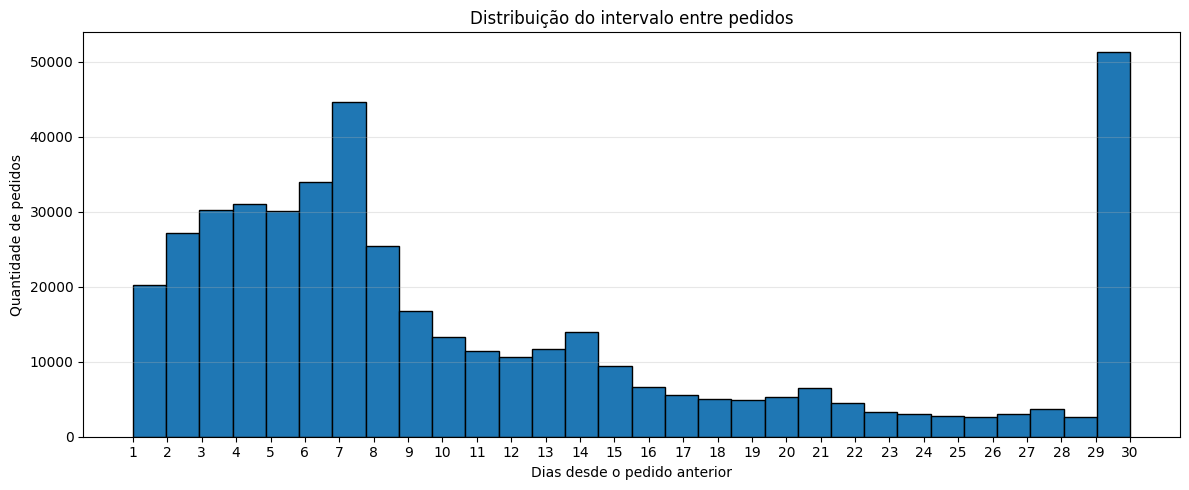

Primeiros pedidos registrados: 9,589
Pedidos com histórico anterior: 440,546


In [49]:
# Separar os primeiros pedidos dos intervalos entre compras
first_orders = (orders['days_since_prior_order'] == 0).sum()

repeat_orders = orders.loc[
    orders['days_since_prior_order'] > 0,
    'days_since_prior_order'
]

# Histograma dos intervalos entre pedidos
plt.figure(figsize=(12, 5))

plt.hist(
    repeat_orders,
    bins=30,
    edgecolor='black'
)

plt.title('Distribuição do intervalo entre pedidos')
plt.xlabel('Dias desde o pedido anterior')
plt.ylabel('Quantidade de pedidos')
plt.xticks(range(1, 31))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Primeiros pedidos registrados: {first_orders:,}')
print(f'Pedidos com histórico anterior: {len(repeat_orders):,}')


**Análise do intervalo entre pedidos**

A distribuição dos intervalos entre pedidos mostra uma concentração significativa de compras recorrentes em períodos curtos, especialmente entre 3 e 7 dias.

O intervalo de 7 dias apresenta um volume expressivo, sugerindo um comportamento de recompra semanal. Também se destaca o intervalo de 30 dias, que registra a maior frequência, indicando a possível existência de um padrão de compras mensal.

Após os primeiros 7 dias, observa-se uma redução geral na frequência dos pedidos, embora existam pequenas elevações em intervalos específicos, como 14 e 21 dias.

**Conclusão:** os dados sugerem que os clientes apresentam diferentes ciclos de recompra, com destaque para os padrões semanal e mensal.

### **4.2 Análise da frequência de pedidos e dos produtos mais comprados**

Nesta etapa, serão investigados os padrões de compra dos clientes, considerando a distribuição dos pedidos ao longo da semana e a frequência de compras por usuário.

A análise será dividida em três partes:

1. **Comparação entre quarta-feira e sábado:** analisar a distribuição dos pedidos por horário (`order_hour_of_day`) nesses dois dias da semana, identificando possíveis diferenças nos padrões de atividade dos consumidores.

2. **Frequência de pedidos por cliente:** construir um gráfico que apresente a quantidade de clientes de acordo com o número de pedidos realizados. Por exemplo, quantos clientes fizeram apenas um pedido, quantos fizeram dois, três e assim sucessivamente.

3. **Produtos mais comprados:** identificar os 20 produtos com maior frequência de compra, apresentando seus respectivos identificadores (`product_id`) e nomes (`product_name`).

O objetivo é compreender possíveis diferenças no comportamento de compra entre os dias analisados, avaliar a frequência de utilização da plataforma pelos clientes e identificar os produtos com maior volume de compras.

In [50]:
# filtrar pedidos de quarta (3) e sábado (6)
wed_orders = orders[orders['order_dow'] == 3]['order_hour_of_day'].value_counts().sort_index()
sat_orders = orders[orders['order_dow'] == 6]['order_hour_of_day'].value_counts().sort_index()

In [51]:
# criar gráfico
import matplotlib.pyplot as plt

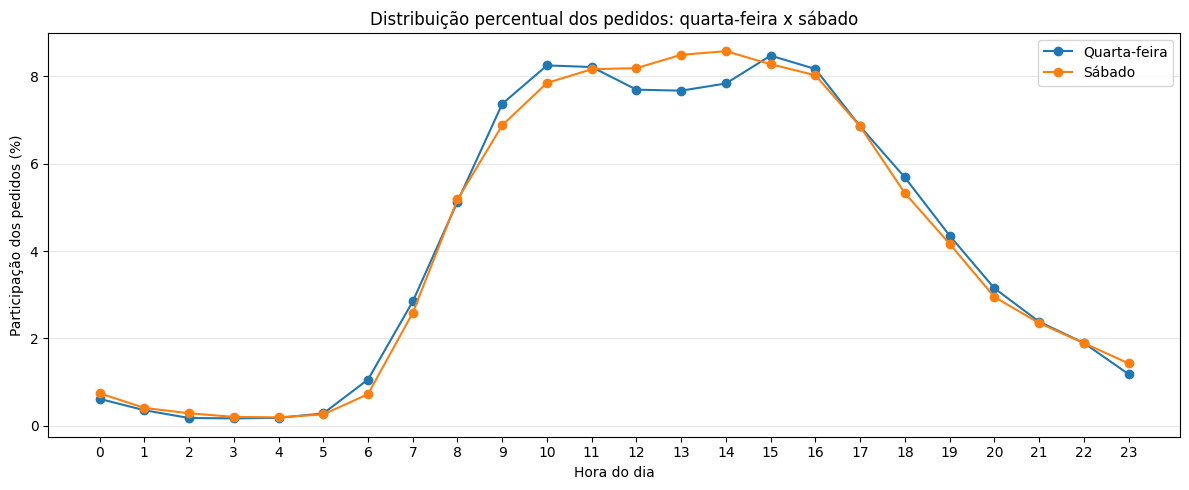

In [52]:
# Comparar a distribuição percentual dos pedidos por hora
wed_pct = wed_orders / wed_orders.sum() * 100
sat_pct = sat_orders / sat_orders.sum() * 100

plt.figure(figsize=(12, 5))

plt.plot(wed_pct.index, wed_pct.values,
         marker='o', label='Quarta-feira')

plt.plot(sat_pct.index, sat_pct.values,
         marker='o', label='Sábado')

plt.title('Distribuição percentual dos pedidos: quarta-feira x sábado')
plt.xlabel('Hora do dia')
plt.ylabel('Participação dos pedidos (%)')
plt.xticks(range(24))
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**Análise comparativa: quarta-feira x sábado**

A comparação percentual da distribuição de pedidos por hora revela padrões bastante semelhantes entre quarta-feira e sábado.

Em ambos os dias, a atividade começa a aumentar a partir das 6h, com crescimento expressivo entre 7h e 10h. A maior concentração de pedidos ocorre entre 10h e 16h, período em que a participação permanece próxima de 8% por hora.

Durante a madrugada, entre 0h e 5h, a participação dos pedidos é reduzida. Após as 16h, observa-se uma diminuição gradual da atividade.

Embora existam pequenas variações em determinados horários, as curvas apresentam comportamento muito próximo.

**Conclusão:** não há diferenças expressivas no padrão de distribuição dos horários de pedidos entre quarta-feira e sábado. O comportamento de compra ao longo do dia é semelhante nos dois períodos.

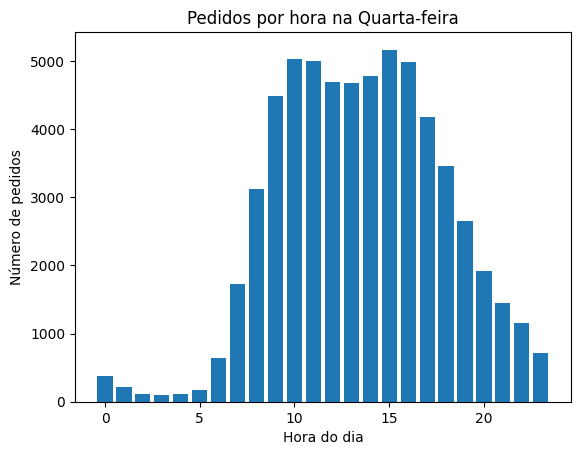

In [53]:
# gráfico de quarta
plt.bar(wed_orders.index, wed_orders.values)
plt.xlabel('Hora do dia')
plt.ylabel('Número de pedidos')
plt.title('Pedidos por hora na Quarta-feira')
plt.show()

**Análise dos pedidos por hora na quarta-feira**

A distribuição dos pedidos ao longo da quarta-feira apresenta maior concentração entre 9h e 16h.

O volume começa a crescer a partir das 6h, com aumento expressivo entre 7h e 10h. Os maiores volumes são observados às 10h e às 15h, com aproximadamente 5 mil pedidos em cada horário.

Após as 16h, observa-se uma redução gradual no número de pedidos, que se torna mais acentuada durante a noite. Na madrugada, entre 1h e 5h, a atividade é significativamente menor.

**Conclusão:** a quarta-feira apresenta maior movimentação durante o período diurno, especialmente entre o final da manhã e a tarde, enquanto a madrugada concentra os menores volumes de pedidos.

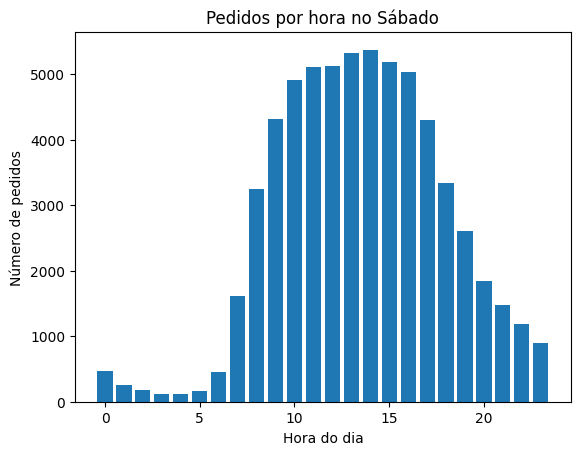

In [54]:
# gráfico de sábado
plt.bar(sat_orders.index, sat_orders.values)
plt.xlabel('Hora do dia')
plt.ylabel('Número de pedidos')
plt.title('Pedidos por hora no Sábado')
plt.show()

**Análise dos pedidos por hora no sábado**

A distribuição dos pedidos aos sábados apresenta maior concentração durante o período diurno, especialmente entre 9h e 16h.

O volume começa a crescer a partir das 6h, com aumento expressivo entre 7h e 10h. O pico de atividade ocorre às 14h, seguido de perto pelos horários das 13h e 15h.

Após as 16h, observa-se uma redução gradual no número de pedidos, que se intensifica durante a noite. Na madrugada, entre 1h e 5h, a atividade também é bastante reduzida.

**Conclusão:** aos sábados, os pedidos concentram-se principalmente entre o final da manhã e o meio da tarde, com maior movimentação às 14h.

In [55]:
# contar quantos pedidos cada cliente fez
orders_per_customer = orders.groupby('user_id')['order_id'].count()
# contar quantos clientes fizeram 1, 2, 3 pedidos...
order_distribution = orders_per_customer.value_counts().sort_index()
import matplotlib.pyplot as plt

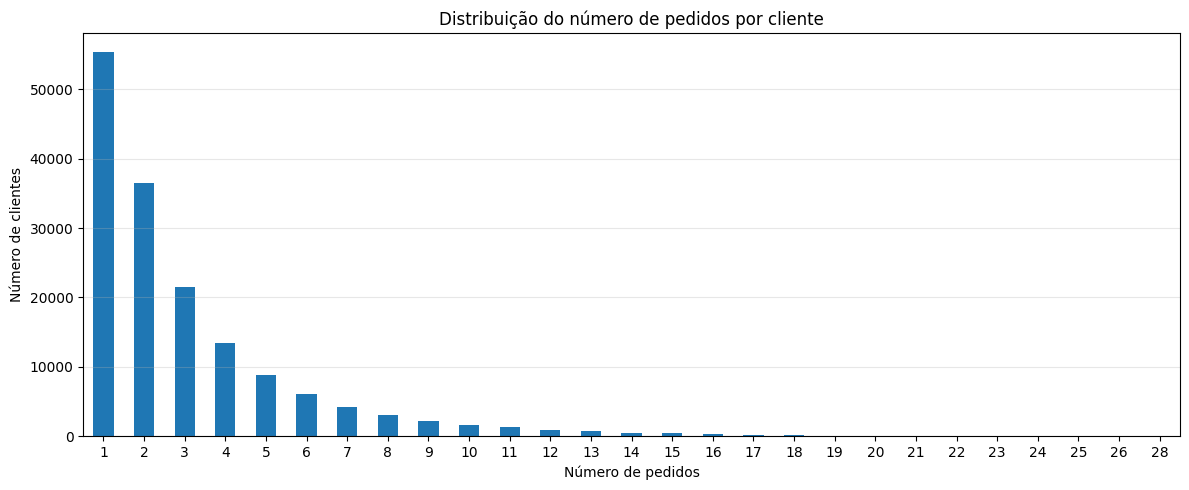

In [56]:
import matplotlib.pyplot as plt
import pandas as pd

# Garante que os dados estejam carregados se o ambiente for reiniciado
try:
    orders
except NameError:
    orders = pd.read_csv('/content/instacart_orders.csv', sep=';')

# Calcula a quantidade de pedidos por cliente
orders_per_customer = orders.groupby('user_id')['order_id'].count()

# Agrupa para contar quantos clientes fizeram 1, 2, 3... pedidos
order_distribution = orders_per_customer.value_counts().sort_index()

plt.figure(figsize=(12, 5))
order_distribution.plot(kind='bar')

plt.title('Distribuição do número de pedidos por cliente')
plt.xlabel('Número de pedidos')
plt.ylabel('Número de clientes')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Análise da distribuição do número de pedidos por cliente**

A distribuição demonstra que a maior parte dos clientes realizou apenas um pedido, com aproximadamente 55 mil registros. Esse número diminui progressivamente conforme aumenta a quantidade de pedidos por cliente.

Clientes que realizaram dois ou três pedidos também representam uma parcela expressiva, mas a frequência de clientes diminui consideravelmente a partir de quatro pedidos.

Observa-se uma distribuição assimétrica à direita, indicando que poucos clientes apresentam uma frequência elevada de compras, enquanto a maioria realiza um número reduzido de pedidos.

**Conclusão:** os dados indicam uma concentração de clientes com baixa frequência de compra e um grupo menor de clientes recorrentes. Esse comportamento pode ser relevante para estratégias de retenção e incentivo à recompra.

In [57]:
# contar quantas vezes cada produto foi pedido
top_products = order_products['product_id'].value_counts().head(20)

In [58]:
# juntar com a tabela de produtos para obter os nomes
top_products = top_products.reset_index()
top_products.columns = ['product_id', 'count']

top_products = top_products.merge(products[['product_id', 'product_name']], on='product_id')

In [59]:
# mostrar resultado
top_products[['product_id', 'product_name']]

,product_id,product_name
0,24852,Banana
1,13176,Bag of Organic Bananas
2,21137,Organic Strawberries
3,21903,Organic Baby Spinach
4,47209,Organic Hass Avocado
5,47766,Organic Avocado
6,47626,Large Lemon
7,16797,Strawberries
8,26209,Limes
9,27845,Organic Whole Milk


**Análise dos 20 produtos mais comprados**

A análise dos 20 produtos com maior volume de compras revelou uma predominância de frutas, vegetais frescos e alimentos orgânicos.

A **banana** ocupa a primeira posição do ranking, seguida por produtos como *Bag of Organic Bananas* e *Organic Strawberries*. Também aparecem entre os itens mais comprados produtos como espinafre, abacate, limão, abobrinha e alho.

Os resultados evidenciam alguns padrões relevantes:

- **Frutas:** banana, morango, maçã e limão aparecem entre os produtos mais comprados.
- **Vegetais frescos:** itens como espinafre, abobrinha e alho também apresentam alta frequência de compra.
- **Produtos orgânicos:** diversos itens do ranking possuem identificação orgânica em seus nomes, indicando uma presença expressiva dessa categoria entre os produtos mais populares.

De modo geral, os resultados mostram que frutas, vegetais e produtos orgânicos ocupam posições de destaque no ranking de compras da plataforma. Esses padrões ajudam a compreender as preferências de consumo dos clientes e podem contribuir para decisões relacionadas à gestão de estoque, disponibilidade de produtos e estratégias comerciais.

### **4.3 Análise do comportamento de compra e dos produtos mais recorrentes**

Nesta etapa, serão analisados o número de itens por pedido, a frequência de recompra de produtos e o comportamento dos clientes em relação aos pedidos repetidos.

As análises serão divididas em cinco partes:

1. **Quantidade de itens por pedido:** identificar quantos itens os clientes normalmente adicionam a cada pedido e analisar a distribuição dessa quantidade.

2. **Produtos mais frequentemente recomprados:** identificar os 20 produtos com maior número de ocorrências de recompra, apresentando seus respectivos IDs e nomes.

3. **Proporção de recompra por produto:** calcular a proporção de ocorrências em que cada produto foi marcado como recompra (`reordered = 1`), organizando os resultados em uma tabela com ID, nome e proporção.

4. **Proporção de pedidos repetidos por cliente:** calcular, para cada cliente, a proporção de seus pedidos que correspondem a recompras.

5. **Produtos adicionados primeiro ao carrinho:** identificar os 20 produtos que mais frequentemente ocupam a primeira posição no carrinho, apresentando o ID, o nome do produto e a quantidade de vezes em que ele foi o primeiro item adicionado.

In [60]:
# contar quantos itens existem em cada pedido
items_per_order = order_products.groupby('order_id')['product_id'].count()

In [61]:
# visualizar a distribuição
import matplotlib.pyplot as plt

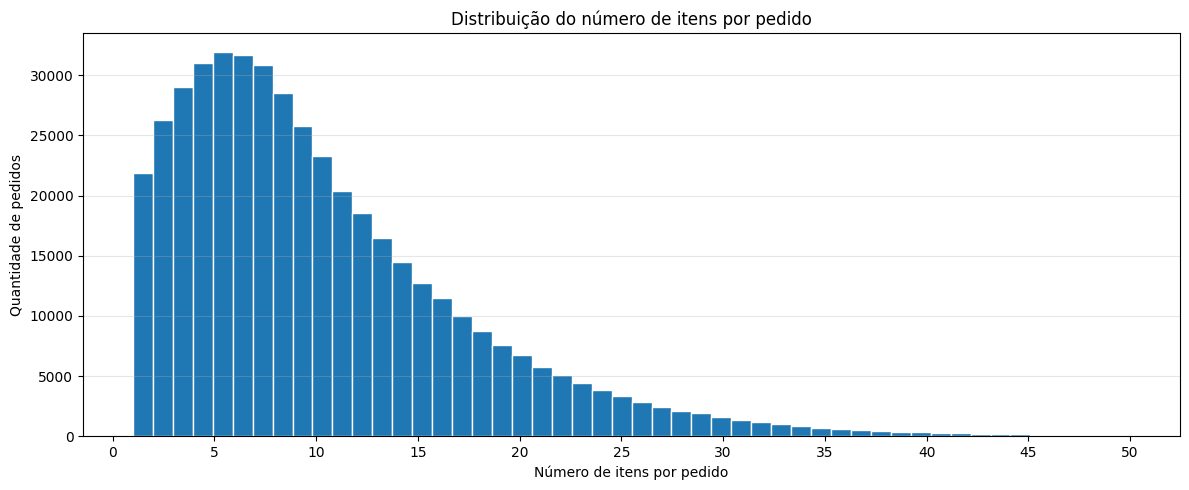

In [62]:
import matplotlib.pyplot as plt
import pandas as pd

# Garante que os dados necessários estejam na memória
try:
    items_per_order
except NameError:
    # Se order_products não estiver carregado, carrega o arquivo
    try:
        order_products
    except NameError:
        order_products = pd.read_csv('/content/order_products.csv.zip', sep=';')
    # Calcula a quantidade de itens por pedido
    items_per_order = order_products.groupby('order_id')['product_id'].count()

plt.figure(figsize=(12, 5))

plt.hist(items_per_order, bins=50, range=(1, 50), edgecolor='white')

plt.title('Distribuição do número de itens por pedido')
plt.xlabel('Número de itens por pedido')
plt.ylabel('Quantidade de pedidos')
plt.xticks(range(0, 51, 5))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Análise da distribuição do número de itens por pedido**

A distribuição demonstra que a maior concentração de pedidos ocorre entre 4 e 8 itens, com pico em torno de 5 a 6 itens por pedido.

À medida que aumenta a quantidade de itens, observa-se uma redução progressiva no número de pedidos. Pedidos com mais de 30 itens são menos frequentes, enquanto pedidos com quantidades muito elevadas representam uma pequena parcela do conjunto analisado.

O histograma apresenta assimetria à direita, indicando que a maioria dos pedidos contém uma quantidade moderada de produtos, enquanto poucos pedidos concentram volumes maiores.

**Conclusão:** os clientes tendem a realizar pedidos de pequeno a médio porte, com maior concentração entre 4 e 8 itens por compra.

In [63]:
# filtrar apenas produtos que foram pedidos novamente
reordered_products = order_products[order_products['reordered'] == 1]

In [64]:
# contar os mais frequentes
top_reordered = reordered_products['product_id'].value_counts().head(20)

In [65]:
# transformar em dataframe
top_reordered = top_reordered.reset_index()
top_reordered.columns = ['product_id', 'count']

In [66]:
import pandas as pd

# Garante que os dados de produtos estejam carregados na memória
try:
    products
except NameError:
    products = pd.read_csv('/content/products.csv', sep=';')

# Garante que os dados necessários estejam na memória e reconstrói top_reordered se necessário
try:
    top_reordered
except NameError:
    # Se order_products não estiver carregado, carrega o arquivo
    try:
        order_products
    except NameError:
        order_products = pd.read_csv('/content/order_products.csv.zip', sep=';')

    # Filtra apenas os produtos que foram reordenados e calcula os 20 mais frequentes
    reordered_products = order_products[order_products['reordered'] == 1]
    top_reordered = reordered_products['product_id'].value_counts().head(20).reset_index()
    top_reordered.columns = ['product_id', 'count']

# Juntar a tabela com os nomes dos produtos
top_reordered = top_reordered.merge(
    products[['product_id', 'product_name']],
    on='product_id'
)

# Exibir os 20 produtos mais comprados novamente
top_reordered = top_reordered.sort_values(
    by='count',
    ascending=False
).reset_index(drop=True)

top_reordered[['product_id', 'product_name', 'count']]

,product_id,product_name,count
0,24852,Banana,55763
1,13176,Bag of Organic Bananas,44450
2,21137,Organic Strawberries,28639
3,21903,Organic Baby Spinach,26233
4,47209,Organic Hass Avocado,23629
5,47766,Organic Avocado,18743
6,27845,Organic Whole Milk,16251
7,47626,Large Lemon,15044
8,27966,Organic Raspberries,14748
9,16797,Strawberries,13945


**Análise dos 20 produtos mais frequentes em pedidos repetidos**

A análise dos produtos com maior frequência de recompra mostra que a Banana ocupa a primeira posição, com 55.763 ocorrências, seguida por Bag of Organic Bananas, com 44.450, e Organic Strawberries, com 28.639.

Também se destacam Organic Baby Spinach, Organic Hass Avocado e Organic Avocado, reforçando a presença de frutas, vegetais e produtos orgânicos entre os itens mais recorrentes.

Observa-se que produtos de consumo cotidiano aparecem com frequência elevada no ranking, sugerindo que esses itens fazem parte das compras habituais dos clientes.

**Conclusão:** bananas, frutas, vegetais e produtos orgânicos apresentam destaque entre os produtos comprados novamente, indicando sua relevância no comportamento de recompra dos consumidores.


In [67]:
# Calcular o total de compras e as recompras por produto
product_reorder = order_products.groupby('product_id').agg(
    total_orders=('reordered', 'count'),
    reordered_orders=('reordered', 'sum')
).reset_index()

# Calcular a taxa de recompra
product_reorder['reorder_ratio'] = (
    product_reorder['reordered_orders'] /
    product_reorder['total_orders']
)

# Adicionar os nomes dos produtos
product_reorder = product_reorder.merge(
    products[['product_id', 'product_name']],
    on='product_id'
)

# Considerar produtos com pelo menos 100 compras
product_reorder = product_reorder[
    product_reorder['total_orders'] >= 100
]

# Ordenar pelos maiores índices de recompra
product_reorder = product_reorder.sort_values(
    by='reorder_ratio',
    ascending=False
)

# Exibir os 20 produtos com maiores taxas de recompra
top_reorder_ratio = product_reorder.head(20).copy()

top_reorder_ratio['reorder_percentage'] = (
    top_reorder_ratio['reorder_ratio'] * 100
).round(2)

top_reorder_ratio[
    ['product_id', 'product_name', 'total_orders',
     'reordered_orders', 'reorder_percentage']
].reset_index(drop=True)

,product_id,product_name,total_orders,reordered_orders,reorder_percentage
0,9292,Half And Half Ultra Pasteurized,397,348,87.66
1,2677,Yerba Mate Sparkling Classic Gold,171,149,87.13
2,47231,Ultra-Purified Water,205,178,86.83
3,1157,Wheat Sandwich Bread,147,127,86.39
4,45504,Whole Organic Omega 3 Milk,1286,1110,86.31
5,29447,Milk- Organic- Vitamin D,2880,2485,86.28
6,34197,Goat Milk,717,616,85.91
7,5514,Organic Homogenized Whole Milk,548,470,85.77
8,31720,Organic Whole Milk,1353,1157,85.51
9,24521,Lowfat Goat Milk,171,146,85.38


**Análise dos produtos com maiores taxas de recompra**

A análise das taxas de recompra, considerando produtos com pelo menos 100 compras, revela índices elevados de recorrência entre os itens selecionados.

O produto Half And Half Ultra Pasteurized apresenta a maior taxa de recompra, com 87,66%, seguido por Yerba Mate Sparkling Classic Gold, com 87,13%, e Ultra-Purified Water, com 86,83%.

Também se destacam produtos lácteos, como Whole Organic Omega 3 Milk e Organic Reduced Fat Milk, indicando uma presença expressiva dessa categoria entre os produtos com maiores taxas de recompra.

A Banana apresenta uma taxa de recompra de 84,43%, mas se diferencia pelo volume expressivo de 66.050 compras, demonstrando elevada recorrência em termos absolutos.

**Conclusão:** os resultados indicam forte recorrência de compra entre determinados produtos, especialmente itens de consumo cotidiano. A análise conjunta da taxa de recompra e do volume de pedidos permite identificar tanto produtos com alta fidelização quanto produtos de grande popularidade.

In [68]:
# calcular total de pedidos por produto
total_orders = order_products.groupby('product_id')['reordered'].count()
# calcular quantos são pedidos repetidos
reordered_orders = order_products.groupby('product_id')['reordered'].sum()
# calcular a proporção
reorder_ratio = reordered_orders / total_orders

In [69]:
# transformar em dataframe
reorder_ratio = reorder_ratio.reset_index()
reorder_ratio.columns = ['product_id', 'reorder_ratio']

In [70]:
# adicionar nome do produto
reorder_ratio = reorder_ratio.merge(products[['product_id', 'product_name']], on='product_id')

# mostrar resultado
reorder_ratio.head()

,product_id,reorder_ratio,product_name
0,1,0.564286,Chocolate Sandwich Cookies
1,2,0.000000,All-Seasons Salt
2,3,0.738095,Robust Golden Unsweetened Oolong Tea
3,4,0.510204,Smart Ones Classic Favorites Mini Rigatoni Wit...
4,7,0.500000,Pure Coconut Water With Orange


**Como interpretar a tabela — Taxa de recompra por produto**

A coluna `reorder_ratio` representa a proporção de vezes em que determinado produto foi comprado novamente, em relação ao total de ocorrências desse produto nos pedidos analisados.

O indicador varia de 0 a 1:
- Valores próximos de 0 indicam que poucas ocorrências do produto foram classificadas como recompras.
- Valores próximos de 1 indicam que uma parcela elevada das ocorrências corresponde a compras repetidas.

**Exemplos dos resultados:**

- **Chocolate Sandwich Cookies (0,56):** aproximadamente 56,43% das ocorrências desse produto correspondem a recompras.
- **All-Seasons Salt (0,00):** nenhuma ocorrência foi classificada como recompra.
- **Robust Golden Unsweetened Oolong Tea (0,74):** aproximadamente 73,81% das ocorrências correspondem a recompras.
- **Smart Ones Classic Favorites Mini Rigatoni (0,51):** cerca de 51,02% das ocorrências correspondem a recompras.
- **Pure Coconut Water With Orange (0,50):** metade das ocorrências corresponde a recompras.

**O que essa métrica permite identificar?**

A taxa de recompra ajuda a compreender a recorrência de consumo dos produtos e a identificar diferenças no comportamento de compra dos clientes.

- **Taxas elevadas:** indicam maior participação de compras repetidas, sugerindo que o produto pode fazer parte dos hábitos recorrentes de consumo.
- **Taxas reduzidas:** indicam menor participação de recompras entre as ocorrências observadas, podendo estar associadas a compras menos recorrentes.

**Conclusão:**

A análise da taxa de recompra permite identificar quais produtos apresentam maior recorrência de consumo. Esse indicador complementa a análise de popularidade, pois um produto pode ter uma quantidade elevada de recompras em termos absolutos, mas uma taxa proporcional diferente. Portanto, avaliar a frequência e a proporção de recompra em conjunto oferece uma visão mais completa do comportamento dos consumidores.

In [71]:
# juntar as tabelas para ter user_id e reordered juntos
merged_data = order_products.merge(orders[['order_id', 'user_id']], on='order_id')
# total de itens por cliente
total_items = merged_data.groupby('user_id')['reordered'].count()
# total de itens repetidos por cliente
reordered_items = merged_data.groupby('user_id')['reordered'].sum()

In [72]:
# proporção de repetição
reorder_ratio_user = reordered_items / total_items

# transformar em dataframe
reorder_ratio_user = reorder_ratio_user.reset_index()
reorder_ratio_user.columns = ['user_id', 'reorder_ratio']

# mostrar resultado
reorder_ratio_user.head()

,user_id,reorder_ratio
0,2,0.038462
1,4,0.000000
2,5,0.666667
3,6,0.000000
4,7,0.928571


**Análise da proporção de itens recomprados por cliente**

Os resultados mostram diferenças no comportamento de compra entre os clientes:

- **Cliente 2 — 0,038 (3,8%):** apresenta uma baixa proporção de itens recomprados, indicando que a maioria dos itens adquiridos não corresponde a recompras.
- **Cliente 4 — 0,00 (0%):** não apresenta registros de itens recomprados na base analisada.
- **Cliente 5 — 0,67 (67%):** apresenta uma proporção elevada de itens recomprados, sugerindo recorrência na aquisição dos mesmos produtos.
- **Cliente 7 — 0,93 (93%):** apresenta uma proporção muito alta de itens recomprados, indicando forte recorrência na escolha dos produtos.

A métrica `reorder_ratio` permite identificar diferentes padrões de comportamento de compra. Valores mais baixos indicam menor participação de itens recomprados no total de itens adquiridos, enquanto valores mais altos representam maior recorrência na compra dos mesmos produtos.

De modo geral, a análise evidencia que os clientes apresentam hábitos de compra distintos: enquanto alguns diversificam mais os produtos adquiridos, outros demonstram maior regularidade na recompra de itens. Esse comportamento é relevante no contexto de compras de supermercado, em que determinados produtos podem fazer parte da rotina de consumo dos clientes.

In [73]:
# filtrar produtos adicionados primeiro ao carrinho
first_cart_items = order_products[order_products['add_to_cart_order'] == 1]
# contar os mais frequentes
top_first_items = first_cart_items['product_id'].value_counts().head(20)

In [74]:
# transformar em dataframe
top_first_items = top_first_items.reset_index()
top_first_items.columns = ['product_id', 'count']

In [75]:
# adicionar os nomes dos produtos
top_first_items = top_first_items.merge(products[['product_id', 'product_name']], on='product_id')
# mostrar resultado
top_first_items[['product_id', 'product_name']]

,product_id,product_name
0,24852,Banana
1,13176,Bag of Organic Bananas
2,27845,Organic Whole Milk
3,21137,Organic Strawberries
4,47209,Organic Hass Avocado
5,21903,Organic Baby Spinach
6,47766,Organic Avocado
7,19660,Spring Water
8,16797,Strawberries
9,27966,Organic Raspberries


**Análise dos produtos adicionados primeiro ao carrinho**

A análise identificou os 20 produtos que aparecem com maior frequência na primeira posição do carrinho, ou seja, aqueles que os clientes adicionam antes dos demais itens.

Entre os produtos mais recorrentes, destacam-se bananas, morangos, abacates, limões, leite orgânico e vegetais frescos. Também aparecem itens como água e bebidas gaseificadas, indicando a diversidade de produtos que ocupam essa posição inicial.

A banana e a *Bag of Organic Bananas* estão entre os itens de maior destaque, reforçando sua presença recorrente nas compras dos clientes.

De modo geral, o resultado mostra que frutas, vegetais, laticínios e outros produtos de consumo frequente aparecem com destaque entre os primeiros itens adicionados ao carrinho. Esse padrão pode sugerir que os clientes costumam iniciar suas compras por produtos habituais ou recorrentes em sua rotina de consumo.

# **5. CONCLUSÃO GERAL**

A análise exploratória dos dados permitiu identificar padrões de compra e compreender diferentes aspectos do comportamento dos clientes da plataforma Instacart. Inicialmente, foi realizada a preparação das cinco bases de dados, com tratamento de valores ausentes, verificação de duplicidades e correção de inconsistências identificadas. Essa etapa possibilitou estruturar os dados para as análises seguintes.

Em relação aos padrões temporais, observou-se que os pedidos se concentram principalmente entre o final da manhã e a tarde. A distribuição também revelou variações no volume de pedidos ao longo dos dias da semana. Quanto ao intervalo entre compras, foram identificados diferentes comportamentos: enquanto alguns clientes realizam novos pedidos após poucos dias, outros apresentam intervalos mais longos, incluindo períodos próximos de um mês.

Na análise dos produtos, frutas, vegetais, laticínios e itens orgânicos tiveram presença expressiva entre os produtos mais comprados e recomprados. A banana, os morangos orgânicos e os abacates estão entre os itens de destaque. Esses produtos também aparecem com frequência entre os primeiros adicionados ao carrinho, evidenciando sua recorrência em diferentes etapas do comportamento de compra.

A análise da proporção de itens recomprados por cliente também revelou diferenças nos hábitos de consumo. Alguns usuários apresentam alta recorrência na aquisição dos mesmos produtos, enquanto outros demonstram menor proporção de recompras, indicando maior diversidade nos itens adquiridos.

De forma geral, os resultados mostram que os clientes apresentam padrões distintos de frequência, recorrência e composição de compras. Essas informações podem contribuir para compreender os hábitos de consumo, identificar produtos com maior demanda e apoiar decisões comerciais relacionadas ao planejamento de estoque, à disponibilidade de produtos e às estratégias de relacionamento com os clientes.